In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv(
    r"C:\Users\sandr\Downloads\luminar\ncr_ride_bookings_cleaned.csv"
)

print(df)

# Convert Date to datetime for time-based analysis
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

              Date      Time    Booking ID   Booking Status   Customer ID  \
0       2024-03-23  12:29:38  "CNR5884300"  No Driver Found  "CID1982111"   
1       2024-11-29  18:01:39  "CNR1326809"       Incomplete  "CID4604802"   
2       2024-08-23  08:56:10  "CNR8494506"        Completed  "CID9202816"   
3       2024-10-21  17:17:25  "CNR8906825"        Completed  "CID2610914"   
4       2024-09-16  22:08:00  "CNR1950162"        Completed  "CID9933542"   
...            ...       ...           ...              ...           ...   
149995  2024-11-11  19:34:01  "CNR6500631"        Completed  "CID4337371"   
149996  2024-11-24  15:55:09  "CNR2468611"        Completed  "CID2325623"   
149997  2024-09-18  10:55:15  "CNR6358306"        Completed  "CID9925486"   
149998  2024-10-05  07:53:34  "CNR3030099"        Completed  "CID9415487"   
149999  2024-03-10  15:38:03  "CNR3447390"        Completed  "CID4108667"   

         Vehicle Type         Pickup Location      Drop Location  Avg VTAT 

In [2]:
# Display the first five rows
print(df.head())

        Date      Time    Booking ID   Booking Status   Customer ID  \
0 2024-03-23  12:29:38  "CNR5884300"  No Driver Found  "CID1982111"   
1 2024-11-29  18:01:39  "CNR1326809"       Incomplete  "CID4604802"   
2 2024-08-23  08:56:10  "CNR8494506"        Completed  "CID9202816"   
3 2024-10-21  17:17:25  "CNR8906825"        Completed  "CID2610914"   
4 2024-09-16  22:08:00  "CNR1950162"        Completed  "CID9933542"   

    Vehicle Type      Pickup Location      Drop Location  Avg VTAT  Avg CTAT  \
0          eBike          Palam Vihar            Jhilmil       NaN       NaN   
1       Go Sedan        Shastri Nagar  Gurgaon Sector 56       4.9      14.0   
2           Auto              Khandsa      Malviya Nagar      13.4      25.8   
3  Premier Sedan  Central Secretariat           Inderlok      13.1      28.5   
4           Bike     Ghitorni Village        Khan Market       5.3      19.6   

   ...  Reason for cancelling by Customer Cancelled Rides by Driver  \
0  ...               

In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (150000, 21)


In [4]:

# Display all column names
print("Columns:", df.columns.tolist())

Columns: ['Date', 'Time', 'Booking ID', 'Booking Status', 'Customer ID', 'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Reason for cancelling by Customer', 'Cancelled Rides by Driver', 'Driver Cancellation Reason', 'Incomplete Rides', 'Incomplete Rides Reason', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Payment Method']


In [5]:
print(df.dtypes)

Date                                 datetime64[us]
Time                                            str
Booking ID                                      str
Booking Status                                  str
Customer ID                                     str
Vehicle Type                                    str
Pickup Location                                 str
Drop Location                                   str
Avg VTAT                                    float64
Avg CTAT                                    float64
Cancelled Rides by Customer                   int64
Reason for cancelling by Customer               str
Cancelled Rides by Driver                     int64
Driver Cancellation Reason                      str
Incomplete Rides                              int64
Incomplete Rides Reason                         str
Booking Value                               float64
Ride Distance                               float64
Driver Ratings                              float64
Customer Rat

In [6]:

# Display summary statistics for all columns
print(df.describe(include="all"))

                              Date      Time    Booking ID Booking Status  \
count                       150000    150000        150000         150000   
unique                         NaN     62910        148767              5   
top                            NaN  17:44:57  "CNR7908610"      Completed   
freq                           NaN        16             3          93000   
mean    2024-06-30 16:42:40.320000       NaN           NaN            NaN   
min            2024-01-01 00:00:00       NaN           NaN            NaN   
25%            2024-03-31 00:00:00       NaN           NaN            NaN   
50%            2024-07-01 00:00:00       NaN           NaN            NaN   
75%            2024-09-30 00:00:00       NaN           NaN            NaN   
max            2024-12-30 00:00:00       NaN           NaN            NaN   
std                            NaN       NaN           NaN            NaN   

         Customer ID Vehicle Type Pickup Location Drop Location  \
count   

In [7]:
# Display summary statistics for numerical columns
print(df.describe())

                             Date       Avg VTAT       Avg CTAT  \
count                      150000  139500.000000  102000.000000   
mean   2024-06-30 16:42:40.320000       8.456352      29.149636   
min           2024-01-01 00:00:00       2.000000      10.000000   
25%           2024-03-31 00:00:00       5.300000      21.600000   
50%           2024-07-01 00:00:00       8.300000      28.800000   
75%           2024-09-30 00:00:00      11.300000      36.800000   
max           2024-12-30 00:00:00      20.000000      45.000000   
std                           NaN       3.773564       8.902577   

       Cancelled Rides by Customer  Cancelled Rides by Driver  \
count                150000.000000              150000.000000   
mean                      0.070000                   0.180000   
min                       0.000000                   0.000000   
25%                       0.000000                   0.000000   
50%                       0.000000                   0.000000   
75%   

In [8]:
# What is the count of each booking status?
print(df["Booking Status"].value_counts())

# What is the percentage of each booking status?
print(df["Booking Status"].value_counts(normalize=True) * 100)

Booking Status
Completed                93000
Cancelled by Driver      27000
No Driver Found          10500
Cancelled by Customer    10500
Incomplete                9000
Name: count, dtype: int64
Booking Status
Completed                62.0
Cancelled by Driver      18.0
No Driver Found           7.0
Cancelled by Customer     7.0
Incomplete                6.0
Name: proportion, dtype: float64


In [9]:
# How many bookings were made for each vehicle type?
print(df["Vehicle Type"].value_counts())

Vehicle Type
Auto             37419
Go Mini          29806
Go Sedan         27141
Bike             22517
Premier Sedan    18111
eBike            10557
Uber XL           4449
Name: count, dtype: int64


In [10]:
# Which pickup locations receive the highest number of bookings?
print(df["Pickup Location"].value_counts().head(10))

Pickup Location
Khandsa             949
Barakhamba Road     946
Saket               931
Badarpur            921
Pragati Maidan      920
Madipur             919
AIIMS               918
Mehrauli            915
Dwarka Sector 21    914
Pataudi Chowk       907
Name: count, dtype: int64


In [11]:
# Which pickup and drop location combinations are most common?
print(
    df.groupby(["Pickup Location", "Drop Location"])["Booking ID"]
      .count()
      .sort_values(ascending=False)
      .head(10)
)


Pickup Location     Drop Location      
DLF City Court      Bhiwadi                17
Akshardham          RK Puram               16
Janakpuri           Faridabad Sector 15    16
Vatika Chowk        Rithala                15
Rithala             Udyog Vihar Phase 4    15
Jor Bagh            Rohini East            15
Ghaziabad           Badshahpur             15
Kashmere Gate ISBT  Tilak Nagar            14
Chirag Delhi        Noida Film City        14
Subhash Nagar       Basai Dhankot          14
Name: Booking ID, dtype: int64


In [12]:
# What percentage of bookings had no driver available?
no_driver_rate = (df["Booking Status"] == "No Driver Found").mean() * 100

print("No Driver Found Rate:", no_driver_rate, "%")

No Driver Found Rate: 7.000000000000001 %


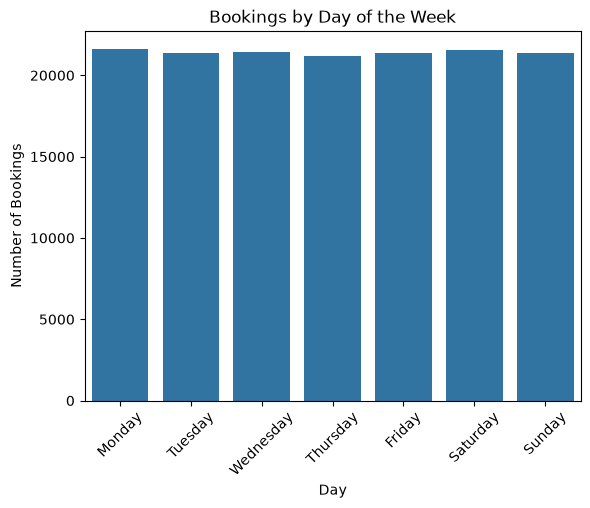

In [13]:
# How does booking demand vary by day of the week?
df["Day of Week"] = df["Date"].dt.day_name()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

sns.countplot(data=df, x="Day of Week", order=day_order)
plt.title("Bookings by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

In [14]:
# How do vehicle arrival and customer trip arrival times differ by booking status?

waiting_time_analysis = df.groupby("Booking Status").agg(
    Average_VTAT=("Avg VTAT", "mean"),
    Average_CTAT=("Avg CTAT", "mean")
)

print(waiting_time_analysis.round(2))

                       Average_VTAT  Average_CTAT
Booking Status                                   
Cancelled by Customer         12.51           NaN
Cancelled by Driver            7.50           NaN
Completed                      8.51         30.03
Incomplete                     6.01         20.00
No Driver Found                 NaN           NaN


In [15]:
# How many bookings were completed successfully?
print((df["Booking Status"] == "Completed").sum())

93000


In [16]:
# What percentage of bookings were cancelled by customers or drivers?
print(df["Booking Status"].isin(
    ["Cancelled by Customer", "Cancelled by Driver"]
).sum() / len(df) * 100)

25.0


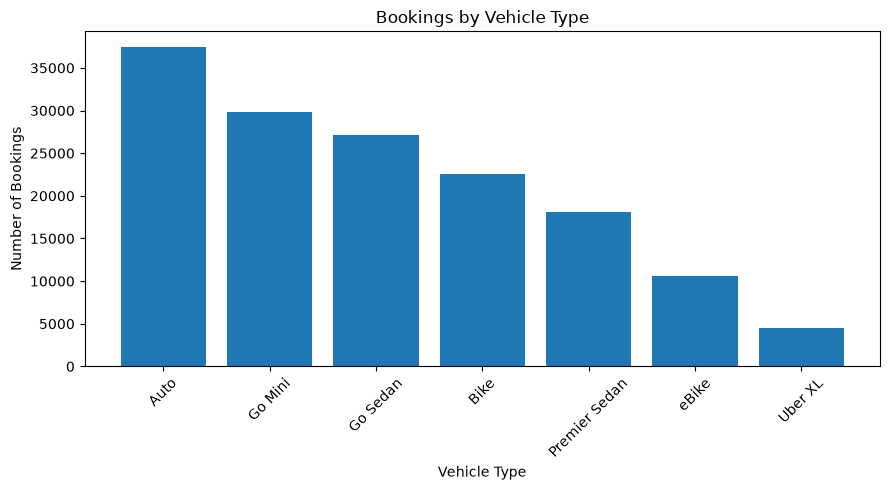

In [17]:
# Which vehicle types receive the most bookings?
plt.figure(figsize=(9, 5))
plt.bar(df["Vehicle Type"].value_counts().index,
        df["Vehicle Type"].value_counts().values)

plt.title("Bookings by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# How many completed rides are there for each vehicle type?
print(df[df["Booking Status"] == "Completed"]["Vehicle Type"].value_counts())

Vehicle Type
Auto             23155
Go Mini          18549
Go Sedan         16676
Bike             14034
Premier Sedan    11252
eBike             6551
Uber XL           2783
Name: count, dtype: int64


In [19]:
# How many bookings occurred on each date?
print(df.groupby("Date")["Booking ID"].count().sort_index())

Date
2024-01-01    414
2024-01-02    389
2024-01-03    384
2024-01-04    414
2024-01-05    416
             ... 
2024-12-26    369
2024-12-27    431
2024-12-28    391
2024-12-29    417
2024-12-30    386
Name: Booking ID, Length: 365, dtype: int64


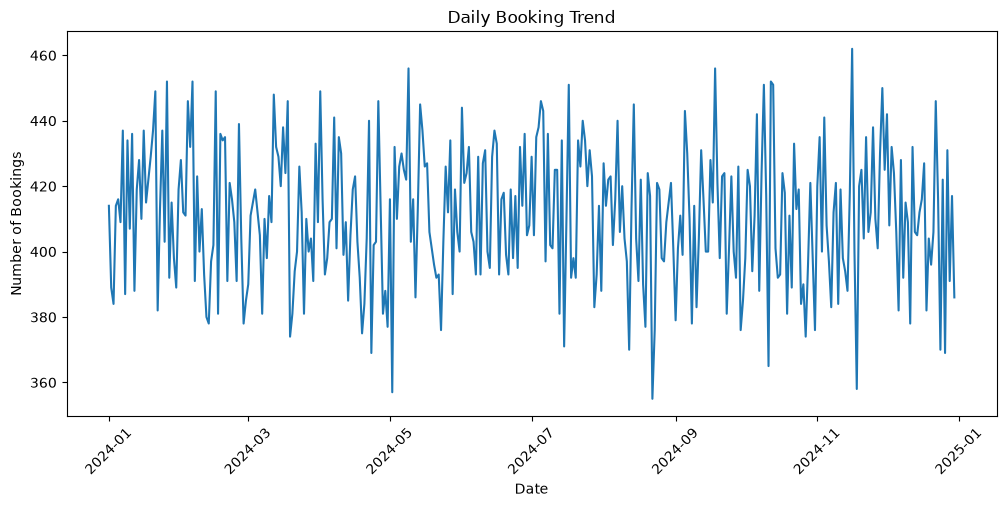

In [20]:
# How does booking demand change over time?
daily_bookings = df.groupby("Date")["Booking ID"].count().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_bookings.index, daily_bookings.values)
plt.title("Daily Booking Trend")
plt.xlabel("Date")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.show()

In [21]:
# How many bookings were cancelled by customers?
print((df["Booking Status"] == "Cancelled by Customer").sum())

10500


In [22]:
# How many bookings were cancelled by drivers?
print((df["Booking Status"] == "Cancelled by Driver").sum())

27000


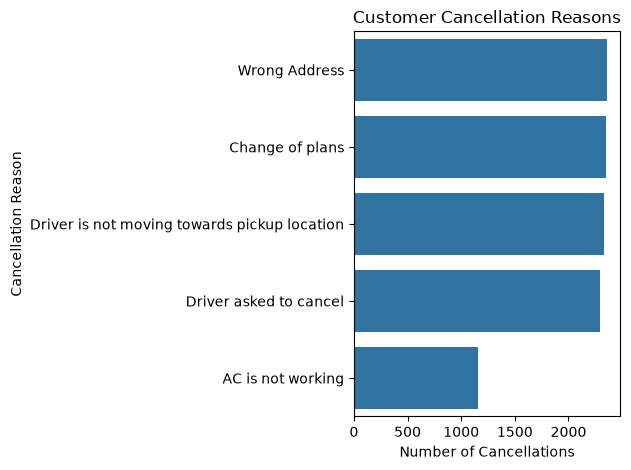

In [23]:
# What are the most common reasons for customer cancellations?
customer_cancel = df[df["Booking Status"] == "Cancelled by Customer"]

sns.countplot(data=customer_cancel,
              y="Reason for cancelling by Customer",
              order=customer_cancel["Reason for cancelling by Customer"].value_counts().index)

plt.title("Customer Cancellation Reasons")
plt.xlabel("Number of Cancellations")
plt.ylabel("Cancellation Reason")
plt.tight_layout()
plt.show()

In [24]:
# What are the most common reasons for driver cancellations?
print(
    df[df["Booking Status"] == "Cancelled by Driver"]
    ["Driver Cancellation Reason"]
    .value_counts()
)

Driver Cancellation Reason
Customer related issue                 6837
The customer was coughing/sick         6751
Personal & Car related issues          6726
More than permitted people in there    6686
Name: count, dtype: int64


In [25]:
# What are the most common reasons for incomplete rides?
print(
    df[df["Booking Status"] == "Incomplete"]
    ["Incomplete Rides Reason"]
    .value_counts()
)

Incomplete Rides Reason
Customer Demand      3040
Vehicle Breakdown    3012
Other Issue          2948
Name: count, dtype: int64


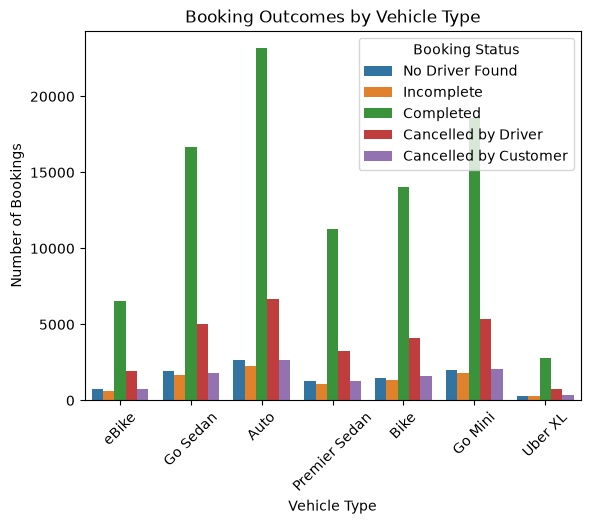

In [26]:
# How do booking outcomes differ across vehicle types?
sns.countplot(data=df, x="Vehicle Type", hue="Booking Status")
plt.title("Booking Outcomes by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)

plt.show()

In [27]:
# What is the average vehicle arrival time?
print(df["Avg VTAT"].mean())

8.456351971326166


In [28]:
# What are the count, mean, median, minimum, and maximum booking values?
print(df["Booking Value"].agg(["count", "mean", "median", "min", "max", "sum"]))

count     1.020000e+05
mean      5.082959e+02
median    4.140000e+02
min       5.000000e+01
max       4.277000e+03
sum       5.184618e+07
Name: Booking Value, dtype: float64


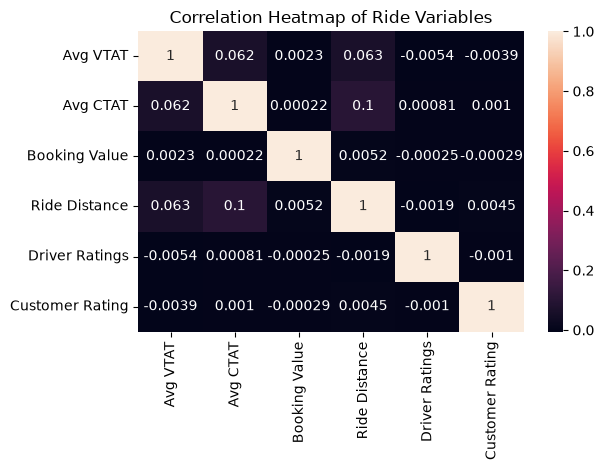

In [29]:
# What is the correlation between important ride-related numerical variables?
sns.heatmap(
    df[["Avg VTAT", "Avg CTAT", "Booking Value",
        "Ride Distance", "Driver Ratings", "Customer Rating"]].corr(),
    annot=True,
    
)
plt.title("Correlation Heatmap of Ride Variables")
plt.tight_layout()
plt.show()

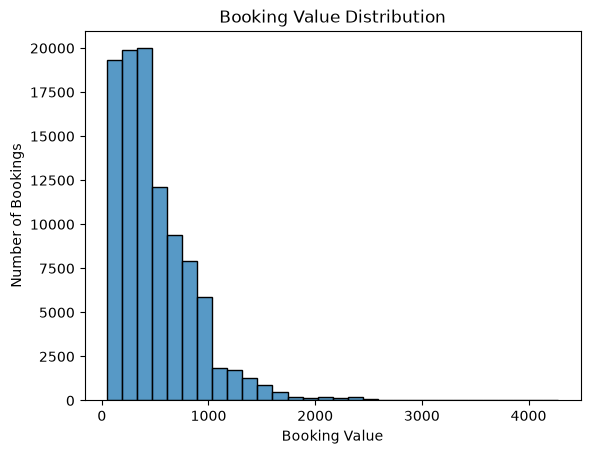

In [30]:
# How are booking values distributed?
sns.histplot(data=df, x="Booking Value", bins=30)
plt.title("Booking Value Distribution")
plt.xlabel("Booking Value")
plt.ylabel("Number of Bookings")
plt.show()

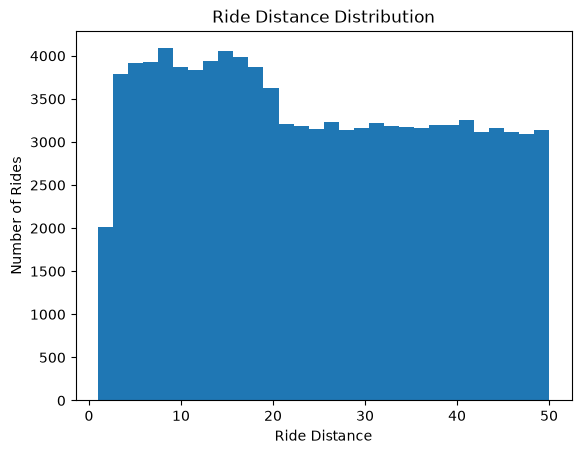

In [31]:
# How are ride distances distributed?
plt.hist(df["Ride Distance"].dropna(), bins=30)
plt.title("Ride Distance Distribution")
plt.xlabel("Ride Distance")
plt.ylabel("Number of Rides")
plt.show()

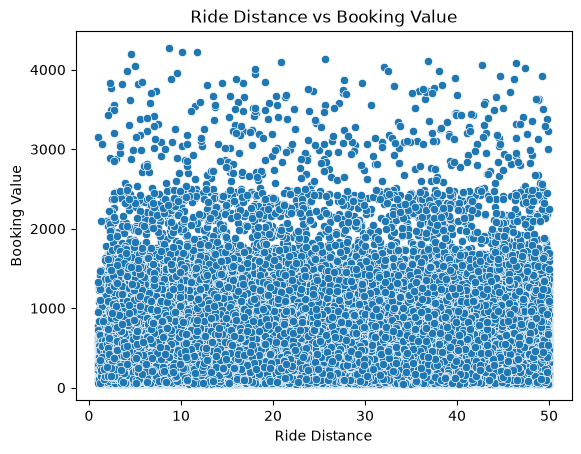

In [32]:
# Is there a relationship between ride distance and booking value?
sns.scatterplot(data=df, x="Ride Distance", y="Booking Value")
plt.title("Ride Distance vs Booking Value")
plt.xlabel("Ride Distance")
plt.ylabel("Booking Value")
plt.show()

In [33]:
# Which vehicle types have the highest average booking value?
print(
    df.groupby("Vehicle Type")["Booking Value"]
    .mean()
    .sort_values(ascending=False)
)

Vehicle Type
Go Sedan         511.503385
Bike             510.200299
Premier Sedan    509.568169
Go Mini          507.684934
Auto             506.725241
eBike            503.897090
Uber XL          501.816749
Name: Booking Value, dtype: float64


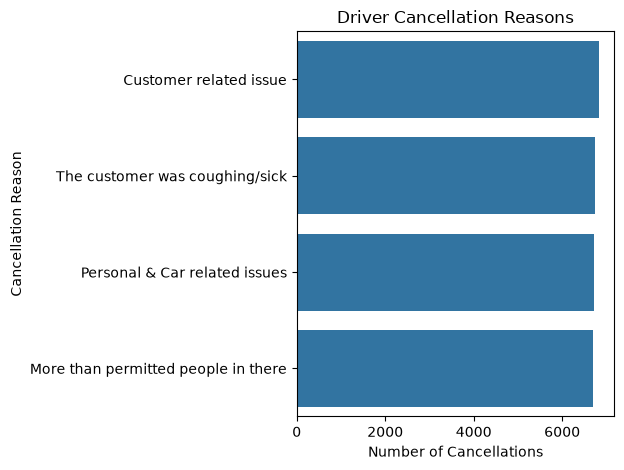

In [34]:
# What are the most common reasons for driver cancellations?
driver_cancel = df[df["Booking Status"] == "Cancelled by Driver"]

sns.countplot(
    data=driver_cancel,
    y="Driver Cancellation Reason",
    order=driver_cancel["Driver Cancellation Reason"].value_counts().index
)
plt.title("Driver Cancellation Reasons")
plt.xlabel("Number of Cancellations")
plt.ylabel("Cancellation Reason")
plt.tight_layout()
plt.show()

In [35]:
# What are the count, mean, median, minimum, and maximum ride distances?
print(df["Ride Distance"].agg(["count", "mean", "median", "min", "max", "sum"]))

count     1.020000e+05
mean      2.463701e+01
median    2.372000e+01
min       1.000000e+00
max       5.000000e+01
sum       2.512975e+06
Name: Ride Distance, dtype: float64


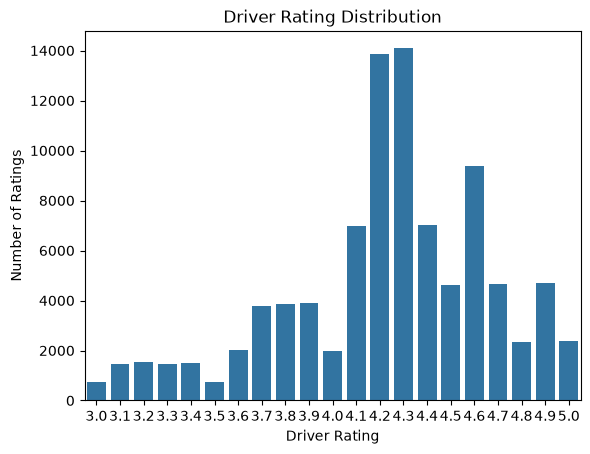

In [36]:
# How are driver ratings distributed?
sns.countplot(data=df, x="Driver Ratings")
plt.title("Driver Rating Distribution")
plt.xlabel("Driver Rating")
plt.ylabel("Number of Ratings")
plt.show()

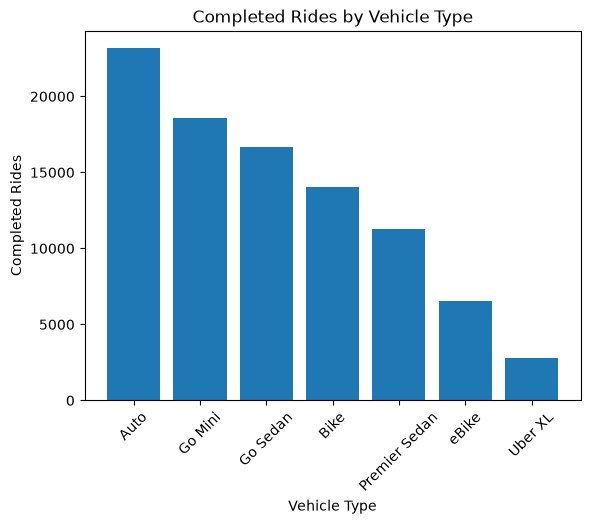

In [37]:
# Which vehicle types have the highest number of completed rides?
completed_vehicle = df[df["Booking Status"] == "Completed"]["Vehicle Type"].value_counts()

plt.bar(completed_vehicle.index, completed_vehicle.values)
plt.title("Completed Rides by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Completed Rides")
plt.xticks(rotation=45)
plt.show()

In [38]:
# Which vehicle types have the highest average ride distance?
print(
    df.groupby("Vehicle Type")["Ride Distance"]
    .mean()
    .sort_values(ascending=False)
)

Vehicle Type
eBike            24.990415
Bike             24.649546
Auto             24.615996
Go Mini          24.612090
Go Sedan         24.609325
Premier Sedan    24.598956
Uber XL          24.402893
Name: Ride Distance, dtype: float64


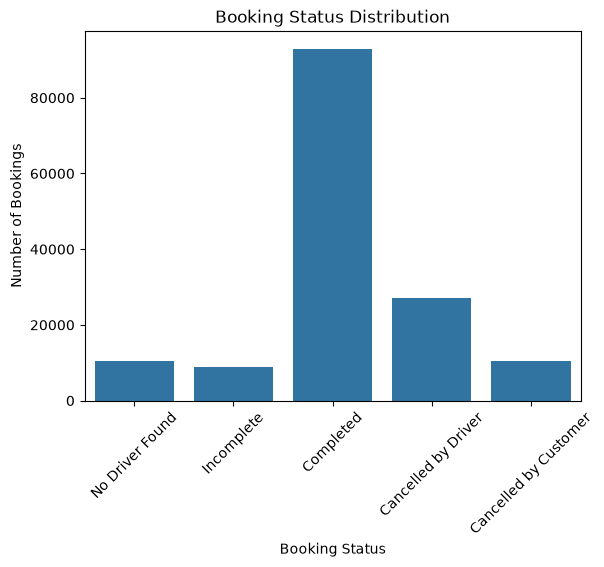

In [39]:
# How are bookings distributed across different booking statuses?
sns.countplot(data=df, x="Booking Status")
plt.title("Booking Status Distribution")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.show()

In [40]:
# What are the count, mean, median, minimum, and maximum customer ratings?
print(df["Customer Rating"].agg(["count", "mean", "median", "min", "max"]))

count     93000.000000
mean          4.404584
median        4.500000
min           3.000000
max           5.000000
Name: Customer Rating, dtype: float64


In [41]:
# How do average driver and customer ratings vary by vehicle type?
print(
    df.groupby("Vehicle Type").agg({
        "Driver Ratings": "mean",
        "Customer Rating": "mean"
    }).sort_values("Driver Ratings", ascending=False).round(2)
)

               Driver Ratings  Customer Rating
Vehicle Type                                  
Uber XL                  4.24             4.40
Premier Sedan            4.23             4.40
Auto                     4.23             4.40
Go Sedan                 4.23             4.41
Bike                     4.23             4.40
Go Mini                  4.23             4.40
eBike                    4.23             4.40


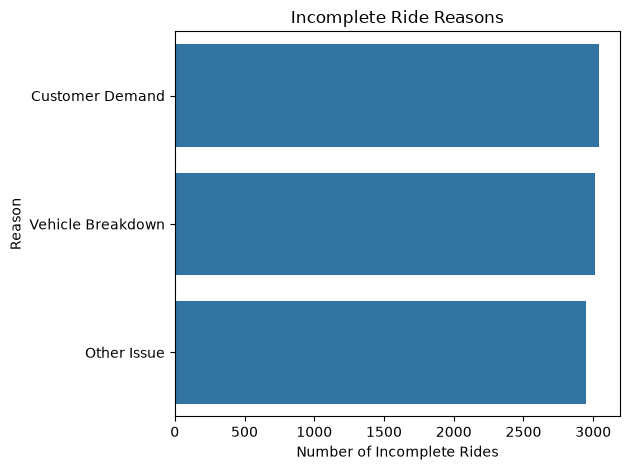

In [42]:
# What are the most common reasons for incomplete rides?
incomplete_rides = df[df["Booking Status"] == "Incomplete"]

sns.countplot(
    data=incomplete_rides,
    y="Incomplete Rides Reason",
    order=incomplete_rides["Incomplete Rides Reason"].value_counts().index
)

plt.title("Incomplete Ride Reasons")
plt.xlabel("Number of Incomplete Rides")
plt.ylabel("Reason")
plt.tight_layout()
plt.show()

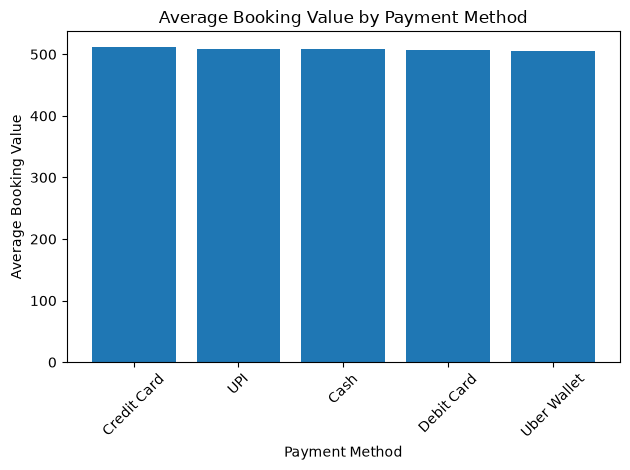

In [43]:
# How does average booking value vary by payment method?
payment_value = df.groupby("Payment Method")["Booking Value"].mean().sort_values(ascending=False)

plt.bar(payment_value.index, payment_value.values)
plt.title("Average Booking Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Booking Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# What are the total and average booking values for each payment method?
print(
    df.groupby("Payment Method")["Booking Value"]
    .agg(["count", "sum", "mean", "median"])
    .sort_values("sum", ascending=False)
    .round(2)
)

                count         sum    mean  median
Payment Method                                   
UPI             45909  23345101.0  508.51   413.0
Cash            25367  12895649.0  508.36   417.0
Uber Wallet     12276   6200898.0  505.12   413.0
Credit Card     10209   5224025.0  511.71   416.0
Debit Card       8239   4180510.0  507.41   413.0


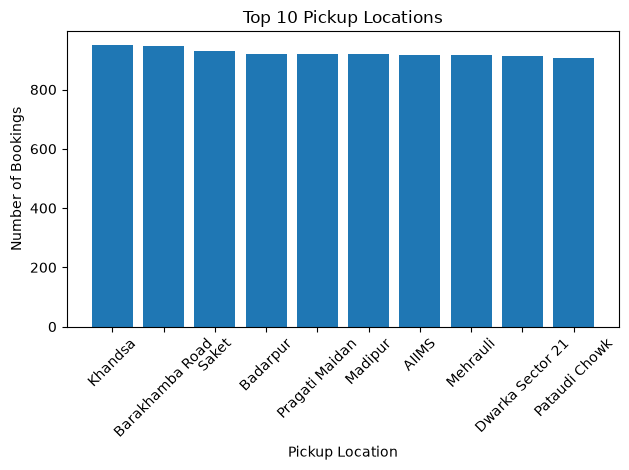

In [45]:
# Which 10 pickup locations receive the most bookings?
pickup_count = df["Pickup Location"].value_counts().head(10)

plt.bar(pickup_count.index, pickup_count.values)
plt.title("Top 10 Pickup Locations")
plt.xlabel("Pickup Location")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
# How are booking outcomes distributed across vehicle types?
print(pd.crosstab(df["Vehicle Type"], df["Booking Status"]))

Booking Status  Cancelled by Customer  Cancelled by Driver  Completed  \
Vehicle Type                                                            
Auto                             2680                 6643      23155   
Bike                             1575                 4077      14034   
Go Mini                          2097                 5330      18549   
Go Sedan                         1832                 5031      16676   
Premier Sedan                    1266                 3250      11252   
Uber XL                           327                  762       2783   
eBike                             723                 1907       6551   

Booking Status  Incomplete  No Driver Found  
Vehicle Type                                 
Auto                  2260             2681  
Bike                  1328             1503  
Go Mini               1815             2015  
Go Sedan              1642             1960  
Premier Sedan         1063             1280  
Uber XL             

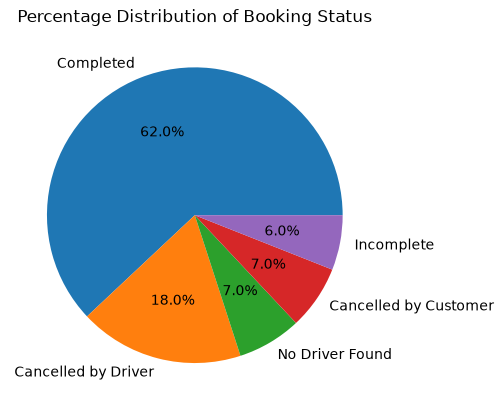

In [47]:
# What percentage of bookings belong to each booking status?
status_count = df["Booking Status"].value_counts()

plt.pie(status_count.values,
        labels=status_count.index,
        autopct="%1.1f%%")

plt.title("Percentage Distribution of Booking Status")
plt.show()